In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Notebook 04: Validation Evaluation

## Campus Road Damage Detection and Severity-Aware Maintenance Prioritization

### Objective

Evaluate the trained YOLOv8n models using the validation
dataset and compare their detailed detection performance.

### Models

- YOLOv8n trained with SGD (16 epochs)
- YOLOv8n trained with AdamW (16 epochs)

### Evaluation Metrics

- Precision
- Recall
- mAP50
- mAP50-95
- Class-wise Average Precision
- Confusion Matrix

## Step 1: Project Setup and Input Verification

In [1]:
# ==========================================
# NOTEBOOK 04 - CELL 1
# Project Setup and Input Verification
# ==========================================

import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define directories
INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working")

DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo"
)

PROJECT_DIR = WORK_DIR / "Validation_Evaluation"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("========== PROJECT SETUP ==========")

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

print("\nWorking directory:", WORK_DIR)
print("Evaluation directory:", PROJECT_DIR)

# ==========================================
# 1. Check GPU
# ==========================================

print("\n========== GPU CHECK ==========")

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

# ==========================================
# 2. Locate saved model weights
# ==========================================

print("\n========== SAVED MODEL WEIGHTS ==========")

model_files = sorted(INPUT_DIR.rglob("best.pt"))

for i, file in enumerate(model_files, 1):

    size_mb = file.stat().st_size / (1024 ** 2)

    print(f"\nModel {i}:")
    print("Path:", file)
    print(f"Size: {size_mb:.2f} MB")

# ==========================================
# 3. Locate epoch 16 checkpoints
# ==========================================

print("\n========== EPOCH 16 CHECKPOINTS ==========")

epoch16_files = sorted(INPUT_DIR.rglob("epoch15.pt"))

for file in epoch16_files:
    print(file)

# ==========================================
# 4. Locate training results
# ==========================================

print("\n========== TRAINING RESULTS ==========")

results_files = sorted(INPUT_DIR.rglob("results.csv"))

for file in results_files:
    print(file)

# ==========================================
# 5. Locate ZIP backups
# ==========================================

print("\n========== ZIP BACKUPS ==========")

for file in sorted(INPUT_DIR.rglob("*.zip")):
    print(file)

print("\n========== SETUP COMPLETED ==========")

========== PROJECT SETUP ==========
Dataset path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
Dataset exists: True

Working directory: /kaggle/working
Evaluation directory: /kaggle/working/Validation_Evaluation

========== GPU CHECK ==========
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== SAVED MODEL WEIGHTS ==========

Model 1:
Path: /kaggle/input/notebooks/ammritkumaar/02-train-baseline-yolov8n/YOLO_Experiments/baseline_yolov8n_sgd-2/weights/best.pt
Size: 12.26 MB

Model 2:
Path: /kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/AdamW_Optimizer_Comparison_Backup/AdamW_Training/weights/best.pt
Size: 30.32 MB

Model 3:
Path: /kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/YOLO_Experiments/optimizer_yolov8n_adamw/weights/best.pt
Size: 30.32 MB

========== EPOCH 16 CHECKPOINTS ==========
/kaggle/input/notebooks/ammritkumaar/02-train-baseline-yolov8n/YOLO_Experiments/baseline_yolov8n_sgd-2/weights/epoch15.pt
/kaggle

## Step 2: Configure Trained Model Paths

Locate and verify the best trained YOLOv8n checkpoints
from the SGD baseline and AdamW optimizer experiments.

Both models were trained for 16 completed epochs using
the same dataset and image resolution.

In [2]:
# ==========================================
# NOTEBOOK 04 - CELL 2
# Configure Trained Model Paths
# ==========================================

from pathlib import Path
import pandas as pd

# ==========================================
# 1. SGD Model Directory
# ==========================================

SGD_RUN_DIR = Path(
    "/kaggle/input/notebooks/ammritkumaar/"
    "02-train-baseline-yolov8n/YOLO_Experiments/"
    "baseline_yolov8n_sgd-2"
)

SGD_MODEL_PATH = SGD_RUN_DIR / "weights/best.pt"
SGD_RESULTS_PATH = SGD_RUN_DIR / "results.csv"

# ==========================================
# 2. AdamW Model Directory
# ==========================================

ADAMW_RUN_DIR = Path(
    "/kaggle/input/notebooks/ammritkumaar/"
    "03-optimizer-comparison/YOLO_Experiments/"
    "optimizer_yolov8n_adamw"
)

ADAMW_MODEL_PATH = ADAMW_RUN_DIR / "weights/best.pt"
ADAMW_RESULTS_PATH = ADAMW_RUN_DIR / "results.csv"

# ==========================================
# 3. Verify Required Files
# ==========================================

print("========== MODEL FILE VERIFICATION ==========")

required_files = {
    "SGD Best Model": SGD_MODEL_PATH,
    "SGD Training Results": SGD_RESULTS_PATH,
    "AdamW Best Model": ADAMW_MODEL_PATH,
    "AdamW Training Results": ADAMW_RESULTS_PATH
}

for name, path in required_files.items():

    assert path.exists(), f"Missing file: {path}"

    print(f"\n{name}")
    print("Exists:", path.exists())
    print("Path:", path)

# ==========================================
# 4. Load Training History
# ==========================================

sgd_df = pd.read_csv(SGD_RESULTS_PATH)
adamw_df = pd.read_csv(ADAMW_RESULTS_PATH)

# Remove extra spaces from column names
sgd_df.columns = sgd_df.columns.str.strip()
adamw_df.columns = adamw_df.columns.str.strip()

print("\n========== TRAINING HISTORY ==========")

print("SGD completed epochs:", len(sgd_df))
print("AdamW completed epochs:", len(adamw_df))

# ==========================================
# 5. Identify Best Validation Epoch
# ==========================================

metric = "metrics/mAP50-95(B)"

sgd_best = sgd_df.loc[sgd_df[metric].idxmax()]
adamw_best = adamw_df.loc[adamw_df[metric].idxmax()]

summary = pd.DataFrame({

    "Model": ["YOLOv8n-SGD", "YOLOv8n-AdamW"],

    "Best Epoch": [
        int(sgd_best["epoch"]),
        int(adamw_best["epoch"])
    ],

    "Precision": [
        sgd_best["metrics/precision(B)"],
        adamw_best["metrics/precision(B)"]
    ],

    "Recall": [
        sgd_best["metrics/recall(B)"],
        adamw_best["metrics/recall(B)"]
    ],

    "mAP50": [
        sgd_best["metrics/mAP50(B)"],
        adamw_best["metrics/mAP50(B)"]
    ],

    "mAP50-95": [
        sgd_best[metric],
        adamw_best[metric]
    ]
})

print("\n========== BEST TRAINING RESULTS ==========")

display(summary.round(5))

print("\n========== MODEL CONFIGURATION COMPLETED ==========")

========== MODEL FILE VERIFICATION ==========

SGD Best Model
Exists: True
Path: /kaggle/input/notebooks/ammritkumaar/02-train-baseline-yolov8n/YOLO_Experiments/baseline_yolov8n_sgd-2/weights/best.pt

SGD Training Results
Exists: True
Path: /kaggle/input/notebooks/ammritkumaar/02-train-baseline-yolov8n/YOLO_Experiments/baseline_yolov8n_sgd-2/results.csv

AdamW Best Model
Exists: True
Path: /kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/YOLO_Experiments/optimizer_yolov8n_adamw/weights/best.pt

AdamW Training Results
Exists: True
Path: /kaggle/input/notebooks/ammritkumaar/03-optimizer-comparison/YOLO_Experiments/optimizer_yolov8n_adamw/results.csv

========== TRAINING HISTORY ==========
SGD completed epochs: 16
AdamW completed epochs: 16

========== BEST TRAINING RESULTS ==========


,Model,Best Epoch,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n-SGD,16,0.51169,0.41295,0.41924,0.19242
1,YOLOv8n-AdamW,16,0.51716,0.44247,0.44259,0.20797



========== MODEL CONFIGURATION COMPLETED ==========


## Step 3: Prepare Validation Dataset

Configure the validation dataset for consistent model
evaluation.

Exclude the previously identified unreadable image
to ensure both models are evaluated on the same
4,752 validation images.

The original dataset remains unchanged.

In [3]:
# ==========================================
# NOTEBOOK 04 - CELL 3
# Prepare Validation Dataset
# ==========================================

import yaml
from pathlib import Path

# ==========================================
# 1. Define Dataset Directories
# ==========================================

VAL_IMAGES_DIR = DATASET_PATH / "images/val"
VAL_LABELS_DIR = DATASET_PATH / "labels/val"

assert VAL_IMAGES_DIR.exists()
assert VAL_LABELS_DIR.exists()

# ==========================================
# 2. Collect Validation Images
# ==========================================

valid_extensions = {".jpg", ".jpeg", ".png"}

val_images = sorted([
    p for p in VAL_IMAGES_DIR.iterdir()
    if p.suffix.lower() in valid_extensions
])

print("========== VALIDATION DATASET ==========")

print("Original validation images:", len(val_images))

# ==========================================
# 3. Exclude Previously Unreadable Image
# ==========================================

EXCLUDED_IMAGE = "China_Drone_001007.jpg"

excluded_images = [
    p for p in val_images
    if p.name == EXCLUDED_IMAGE
]

valid_images = [
    p for p in val_images
    if p.name != EXCLUDED_IMAGE
]

print("\nExcluded image:", EXCLUDED_IMAGE)
print("Excluded images:", len(excluded_images))
print("Final validation images:", len(valid_images))

assert len(val_images) == 4753
assert len(excluded_images) == 1
assert len(valid_images) == 4752

# ==========================================
# 4. Verify Corresponding Labels
# ==========================================

missing_labels = []

for image_path in valid_images:

    label_path = VAL_LABELS_DIR / (
        image_path.stem + ".txt"
    )

    if not label_path.exists():
        missing_labels.append(image_path.name)

print("\n========== LABEL VERIFICATION ==========")

print("Valid images:", len(valid_images))
print("Missing labels:", len(missing_labels))

assert len(missing_labels) == 0

# ==========================================
# 5. Create Validation Image List
# ==========================================

VAL_LIST_PATH = WORK_DIR / "validation_images.txt"

with open(VAL_LIST_PATH, "w") as f:

    for image_path in valid_images:
        f.write(str(image_path) + "\n")

print("\nValidation image list saved:")
print(VAL_LIST_PATH)

# ==========================================
# 6. Create Evaluation YAML
# ==========================================

evaluation_config = {

    "path": str(DATASET_PATH),

    "train": "images/train",

    "val": str(VAL_LIST_PATH),

    "test": "images/test",

    "nc": 4,

    "names": {
        0: "Longitudinal Crack",
        1: "Transverse Crack",
        2: "Alligator Crack",
        3: "Pothole"
    }
}

EVAL_YAML_PATH = WORK_DIR / "evaluation_data.yaml"

with open(EVAL_YAML_PATH, "w") as f:

    yaml.safe_dump(
        evaluation_config,
        f,
        sort_keys=False
    )

print("\n========== EVALUATION YAML ==========")

with open(EVAL_YAML_PATH, "r") as f:
    print(f.read())

print("========== DATASET PREPARATION COMPLETED ==========")

========== VALIDATION DATASET ==========
Original validation images: 4753

Excluded image: China_Drone_001007.jpg
Excluded images: 1
Final validation images: 4752

========== LABEL VERIFICATION ==========
Valid images: 4752
Missing labels: 0

Validation image list saved:
/kaggle/working/validation_images.txt

========== EVALUATION YAML ==========
path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
train: images/train
val: /kaggle/working/validation_images.txt
test: images/test
nc: 4
names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole

========== DATASET PREPARATION COMPLETED ==========


## Step 4: Install Ultralytics and Verify Environment

Install the same Ultralytics version used during model
training to maintain consistency across experiments.

Verify the GPU environment, trained model checkpoints,
and evaluation dataset configuration before validation.

In [4]:
# ==========================================
# NOTEBOOK 04 - CELL 4
# Install Ultralytics and Environment Setup
# ==========================================

# Install same version used during training
!pip install -q ultralytics==8.4.211

import torch
import ultralytics
from ultralytics import YOLO

# ==========================================
# 1. Environment Verification
# ==========================================

print("========== ENVIRONMENT CHECK ==========")

print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", ultralytics.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

assert torch.cuda.is_available(), "GPU not available!"

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

# ==========================================
# 2. Evaluation Configuration
# ==========================================

IMG_SIZE = 640
BATCH_SIZE = 32
DEVICE = 0

print("\n========== EVALUATION SETTINGS ==========")

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Device:", DEVICE)
print("Evaluation Split: val")

# ==========================================
# 3. Verify Required Files
# ==========================================

assert SGD_MODEL_PATH.exists()
assert ADAMW_MODEL_PATH.exists()
assert EVAL_YAML_PATH.exists()
assert VAL_LIST_PATH.exists()

print("\n========== FILE VERIFICATION ==========")

print("SGD Model:", SGD_MODEL_PATH.exists())
print("AdamW Model:", ADAMW_MODEL_PATH.exists())
print("Evaluation YAML:", EVAL_YAML_PATH.exists())
print("Validation Image List:", VAL_LIST_PATH.exists())

# ==========================================
# 4. Load Both Trained Models
# ==========================================

print("\n========== LOADING TRAINED MODELS ==========")

sgd_model = YOLO(str(SGD_MODEL_PATH))
print("SGD model loaded successfully!")

adamw_model = YOLO(str(ADAMW_MODEL_PATH))
print("AdamW model loaded successfully!")

# Verify model classes
print("\nSGD Classes:", sgd_model.names)
print("AdamW Classes:", adamw_model.names)

assert sgd_model.names == adamw_model.names

print("\n========== ENVIRONMENT READY ==========")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== ENVIRONMENT CHECK ==========
PyTorch Version: 2.11.0+cu130
Ultralytics Version: 8.4.211
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== EVALUATION SETTINGS ==========
Image Size: 640
Batch Size: 32
Device: 0
Evaluation Split: val

========== FILE VERIFICATION ==========
SGD Model: True
AdamW Model: True
Evaluation YAML: True
Validation Image List: True

========== LOADING TRAINED MODELS ==========
SGD model loaded successfully!
AdamW model loaded successfully!

SGD Classes: {0: 'Longitudinal Crack', 1: 'Transverse Crack', 2: 'Alligator Crack', 3: 'Pothole'}
AdamW Classes: {0: 'Longitudinal Crack', 1: 'Transverse Crack', 2: 'Alligator Crack', 3: 'Pothole'}

==

## Step 5: Validate SGD Baseline Model

Evaluate the trained YOLOv8n-SGD model on the
4,752-image validation dataset.

Calculate overall and class-wise detection metrics,
generate confusion matrices and performance curves,
and record inference speed for further comparison.

No additional model training is performed.

In [5]:
# ==========================================
# NOTEBOOK 04 - CELL 5
# Validate SGD Baseline Model
# ==========================================

import time
import pandas as pd
from ultralytics import YOLO

print("========== SGD MODEL VALIDATION ==========")

# Load trained SGD model
sgd_model = YOLO(str(SGD_MODEL_PATH))

# Record start time
start_time = time.time()

# ==========================================
# 1. Run Validation
# ==========================================

sgd_metrics = sgd_model.val(

    data=str(EVAL_YAML_PATH),

    split="val",

    imgsz=IMG_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=2,

    conf=0.001,

    iou=0.7,

    max_det=300,

    half=True,

    plots=True,

    project=str(PROJECT_DIR),

    name="SGD_Validation",

    exist_ok=True,

    verbose=True
)

# Calculate evaluation time
sgd_eval_time = time.time() - start_time

# ==========================================
# 2. Overall Evaluation Metrics
# ==========================================

sgd_overall = pd.DataFrame({

    "Model": ["YOLOv8n-SGD"],

    "Precision": [sgd_metrics.box.mp],

    "Recall": [sgd_metrics.box.mr],

    "mAP50": [sgd_metrics.box.map50],

    "mAP50-95": [sgd_metrics.box.map],

    "Evaluation Time (min)": [sgd_eval_time / 60],

    "Inference Time (ms/image)": [
        sgd_metrics.speed["inference"]
    ]
})

print("\n========== SGD OVERALL METRICS ==========")

display(sgd_overall.round(5))

# ==========================================
# 3. Class-wise Evaluation Metrics
# ==========================================

class_results = []

for i, class_id in enumerate(
    sgd_metrics.box.ap_class_index
):

    class_id = int(class_id)

    class_results.append({

        "Class ID": class_id,

        "Class Name": sgd_model.names[class_id],

        "Precision": sgd_metrics.box.p[i],

        "Recall": sgd_metrics.box.r[i],

        "mAP50": sgd_metrics.box.ap50[i],

        "mAP50-95": sgd_metrics.box.ap[i]
    })

sgd_classwise = pd.DataFrame(class_results)

print("\n========== SGD CLASS-WISE METRICS ==========")

display(sgd_classwise.round(5))

# ==========================================
# 4. Save Evaluation Results
# ==========================================

SGD_VAL_DIR = Path(sgd_metrics.save_dir)

sgd_overall.to_csv(
    SGD_VAL_DIR / "sgd_overall_metrics.csv",
    index=False
)

sgd_classwise.to_csv(
    SGD_VAL_DIR / "sgd_classwise_metrics.csv",
    index=False
)

print("\n========== EVALUATION TIME ==========")

print(f"Total time: {sgd_eval_time / 60:.2f} minutes")

# ==========================================
# 5. Display Saved Files
# ==========================================

print("\n========== SAVED RESULTS ==========")

print("Results directory:", SGD_VAL_DIR)

for file in sorted(SGD_VAL_DIR.iterdir()):
    print(file.name)

print("\n========== SGD VALIDATION COMPLETED ==========")

========== SGD MODEL VALIDATION ==========
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 3.1±3.3 MB/s, size: 383.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels/val... 4752 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4752/4752 20.4it/s 3:530.1ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 149/149 1.9s/it 4:440.3ss
                   all

,Model,Precision,Recall,mAP50,mAP50-95,Evaluation Time (min),Inference Time (ms/image)
0,YOLOv8n-SGD,0.51125,0.41278,0.41912,0.19232,8.89317,2.95689



========== SGD CLASS-WISE METRICS ==========


,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,Longitudinal Crack,0.47323,0.45114,0.42076,0.20544
1,1,Transverse Crack,0.49552,0.43753,0.41914,0.17784
2,2,Alligator Crack,0.52532,0.56046,0.54874,0.27209
3,3,Pothole,0.55093,0.20201,0.28785,0.11390



========== EVALUATION TIME ==========
Total time: 8.89 minutes

========== SAVED RESULTS ==========
Results directory: /kaggle/working/Validation_Evaluation/SGD_Validation
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
sgd_classwise_metrics.csv
sgd_overall_metrics.csv
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

========== SGD VALIDATION COMPLETED ==========


## Step 6: Validate AdamW Model

Evaluate the trained YOLOv8n-AdamW model using the
same validation dataset and evaluation settings as
the SGD baseline model.

Record overall metrics, class-wise detection performance,
confusion matrices, performance curves, and inference
speed for a fair comparison.

In [6]:
# ==========================================
# NOTEBOOK 04 - CELL 6
# Validate AdamW Model
# ==========================================

import time
import pandas as pd
from ultralytics import YOLO

print("========== ADAMW MODEL VALIDATION ==========")

# Load trained AdamW model
adamw_model = YOLO(str(ADAMW_MODEL_PATH))

# Record start time
start_time = time.time()

# ==========================================
# 1. Run Validation
# ==========================================

adamw_metrics = adamw_model.val(

    data=str(EVAL_YAML_PATH),

    split="val",

    imgsz=IMG_SIZE,

    batch=BATCH_SIZE,

    device=DEVICE,

    workers=2,

    conf=0.001,

    iou=0.7,

    max_det=300,

    half=True,

    plots=True,

    project=str(PROJECT_DIR),

    name="AdamW_Validation",

    exist_ok=True,

    verbose=True
)

# Calculate evaluation time
adamw_eval_time = time.time() - start_time

# ==========================================
# 2. Overall Evaluation Metrics
# ==========================================

adamw_overall = pd.DataFrame({

    "Model": ["YOLOv8n-AdamW"],

    "Precision": [adamw_metrics.box.mp],

    "Recall": [adamw_metrics.box.mr],

    "mAP50": [adamw_metrics.box.map50],

    "mAP50-95": [adamw_metrics.box.map],

    "Evaluation Time (min)": [
        adamw_eval_time / 60
    ],

    "Inference Time (ms/image)": [
        adamw_metrics.speed["inference"]
    ]
})

print("\n========== ADAMW OVERALL METRICS ==========")

display(adamw_overall.round(5))

# ==========================================
# 3. Class-wise Evaluation Metrics
# ==========================================

class_results = []

for i, class_id in enumerate(
    adamw_metrics.box.ap_class_index
):

    class_id = int(class_id)

    class_results.append({

        "Class ID": class_id,

        "Class Name": adamw_model.names[class_id],

        "Precision": adamw_metrics.box.p[i],

        "Recall": adamw_metrics.box.r[i],

        "mAP50": adamw_metrics.box.ap50[i],

        "mAP50-95": adamw_metrics.box.ap[i]
    })

adamw_classwise = pd.DataFrame(class_results)

print("\n========== ADAMW CLASS-WISE METRICS ==========")

display(adamw_classwise.round(5))

# ==========================================
# 4. Save Evaluation Results
# ==========================================

ADAMW_VAL_DIR = Path(adamw_metrics.save_dir)

adamw_overall.to_csv(
    ADAMW_VAL_DIR / "adamw_overall_metrics.csv",
    index=False
)

adamw_classwise.to_csv(
    ADAMW_VAL_DIR / "adamw_classwise_metrics.csv",
    index=False
)

print("\n========== EVALUATION TIME ==========")

print(f"Total time: {adamw_eval_time / 60:.2f} minutes")

# ==========================================
# 5. Display Saved Files
# ==========================================

print("\n========== SAVED RESULTS ==========")

print("Results directory:", ADAMW_VAL_DIR)

for file in sorted(ADAMW_VAL_DIR.iterdir()):
    print(file.name)

print("\n========== ADAMW VALIDATION COMPLETED ==========")

========== ADAMW MODEL VALIDATION ==========
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 152.6±12.2 MB/s, size: 76.1 KB)
val: Scanning /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels/val... 4752 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4752/4752 878.2it/s 5.4s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 149/149 3.5it/s 42.3s0.2ss
                   all       4752      11016      0.518      0.443      0.443      0.208
    Longitudinal Crack       2669       5147      0.511      0.452      0.446      

,Model,Precision,Recall,mAP50,mAP50-95,Evaluation Time (min),Inference Time (ms/image)
0,YOLOv8n-AdamW,0.51797,0.44269,0.44299,0.20805,0.91684,2.23629



========== ADAMW CLASS-WISE METRICS ==========


,Class ID,Class Name,Precision,Recall,mAP50,mAP50-95
0,0,Longitudinal Crack,0.51107,0.45191,0.44567,0.22438
1,1,Transverse Crack,0.50797,0.47056,0.44101,0.19383
2,2,Alligator Crack,0.57261,0.54454,0.56435,0.28211
3,3,Pothole,0.48025,0.30376,0.32093,0.13189



========== EVALUATION TIME ==========
Total time: 0.92 minutes

========== SAVED RESULTS ==========
Results directory: /kaggle/working/Validation_Evaluation/AdamW_Validation
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
adamw_classwise_metrics.csv
adamw_overall_metrics.csv
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

========== ADAMW VALIDATION COMPLETED ==========


## Step 7: Compare Models and Select Best Model

Compare the standalone validation results of YOLOv8n-SGD
and YOLOv8n-AdamW using overall and class-wise metrics.

Select the best model based on validation mAP50-95
for subsequent independent test evaluation.

Generate comparison tables, performance improvement
statistics, and visualization plots.

========== OVERALL COMPARISON ==========


,Model,Precision,Recall,mAP50,mAP50-95,Evaluation Time (min),Inference Time (ms/image)
0,YOLOv8n-SGD,0.51125,0.41278,0.41912,0.19232,8.89317,2.95689
1,YOLOv8n-AdamW,0.51797,0.44269,0.44299,0.20805,0.91684,2.23629



========== PERFORMANCE IMPROVEMENT ==========


,Metric,SGD (%),AdamW (%),Improvement (percentage points)
0,Precision,51.125,51.797,0.672
1,Recall,41.278,44.269,2.991
2,mAP50,41.912,44.299,2.387
3,mAP50-95,19.232,20.805,1.573



========== CLASS-WISE COMPARISON ==========


,Class ID,Class Name,Precision_SGD,Recall_SGD,mAP50_SGD,mAP50-95_SGD,Precision_AdamW,Recall_AdamW,mAP50_AdamW,mAP50-95_AdamW,mAP50 Improvement (pp),mAP50-95 Improvement (pp)
0,0,Longitudinal Crack,0.47323,0.45114,0.42076,0.20544,0.51107,0.45191,0.44567,0.22438,2.49152,1.89448
1,1,Transverse Crack,0.49552,0.43753,0.41914,0.17784,0.50797,0.47056,0.44101,0.19383,2.18641,1.59863
2,2,Alligator Crack,0.52532,0.56046,0.54874,0.27209,0.57261,0.54454,0.56435,0.28211,1.56120,1.00123
3,3,Pothole,0.55093,0.20201,0.28785,0.11390,0.48025,0.30376,0.32093,0.13189,3.30751,1.79928


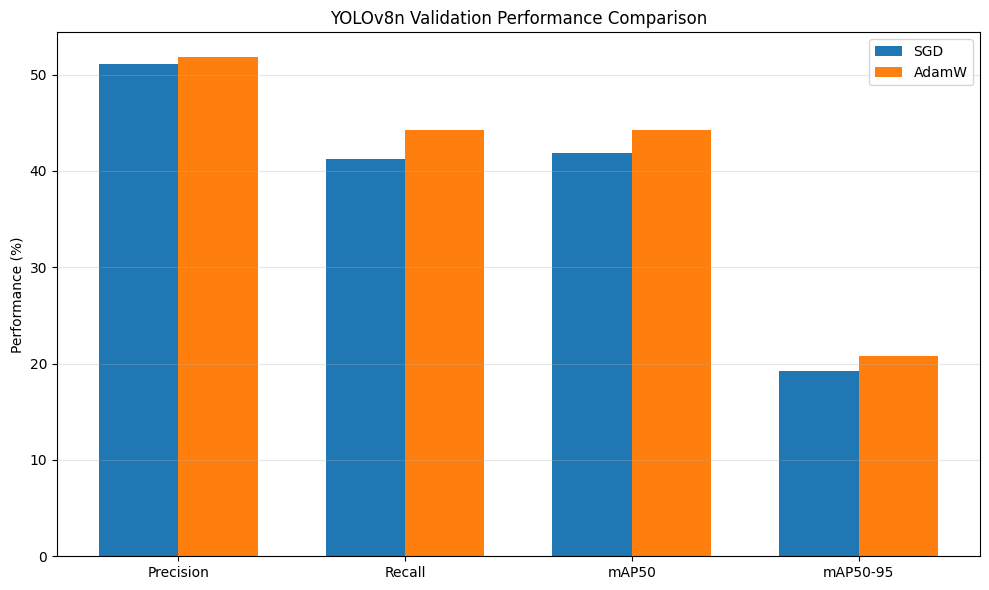

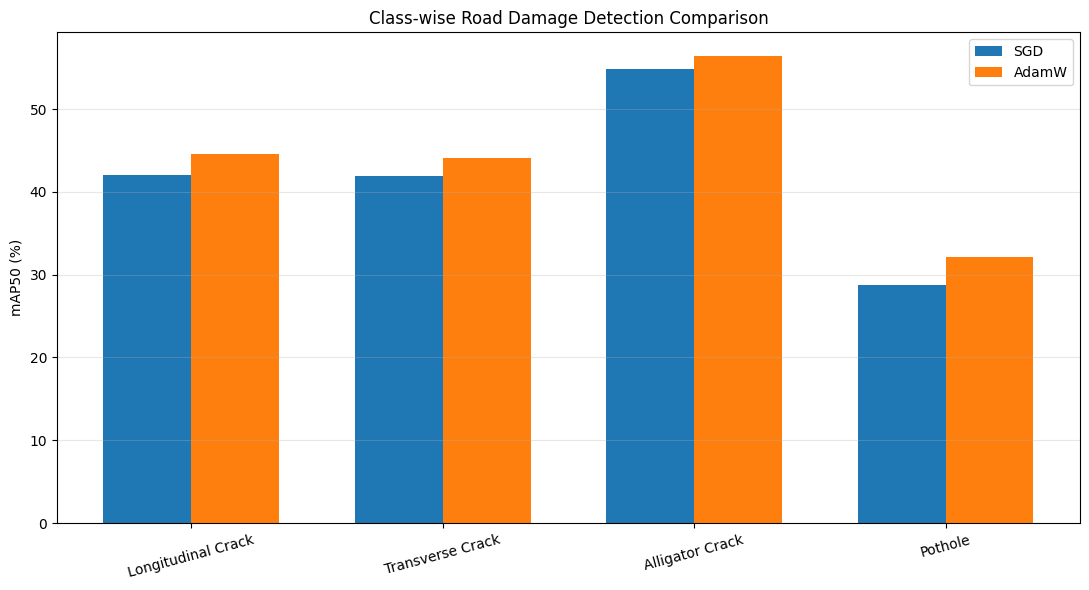


========== BEST MODEL SELECTED ==========
Selected Model: YOLOv8n-AdamW
Validation mAP50: 44.3 %
Validation mAP50-95: 20.81 %

Selected model saved at:
/kaggle/working/Validation_Evaluation/Selected_Model/best_model.pt

========== MODEL COMPARISON COMPLETED ==========


In [7]:
# ==========================================
# NOTEBOOK 04 - CELL 7
# Compare Models and Select Best Model
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shutil
import json
from pathlib import Path

# ==========================================
# 1. Create Comparison Directory
# ==========================================

COMPARISON_DIR = PROJECT_DIR / "Model_Comparison"

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 2. Compare Overall Metrics
# ==========================================

overall_comparison = pd.concat(
    [sgd_overall, adamw_overall],
    ignore_index=True
)

print("========== OVERALL COMPARISON ==========")

display(overall_comparison.round(5))

overall_comparison.to_csv(
    COMPARISON_DIR / "overall_comparison.csv",
    index=False
)

# ==========================================
# 3. Calculate Performance Improvement
# ==========================================

metric_names = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

improvement_rows = []

for metric in metric_names:

    sgd_value = sgd_overall[metric].iloc[0]
    adamw_value = adamw_overall[metric].iloc[0]

    improvement_rows.append({

        "Metric": metric,

        "SGD (%)": sgd_value * 100,

        "AdamW (%)": adamw_value * 100,

        "Improvement (percentage points)":
            (adamw_value - sgd_value) * 100
    })

improvement_df = pd.DataFrame(
    improvement_rows
)

print("\n========== PERFORMANCE IMPROVEMENT ==========")

display(improvement_df.round(3))

improvement_df.to_csv(
    COMPARISON_DIR / "performance_improvement.csv",
    index=False
)

# ==========================================
# 4. Compare Class-wise Performance
# ==========================================

class_comparison = pd.merge(

    sgd_classwise,

    adamw_classwise,

    on=["Class ID", "Class Name"],

    suffixes=("_SGD", "_AdamW")
)

class_comparison["mAP50 Improvement (pp)"] = (

    class_comparison["mAP50_AdamW"]
    - class_comparison["mAP50_SGD"]

) * 100

class_comparison["mAP50-95 Improvement (pp)"] = (

    class_comparison["mAP50-95_AdamW"]
    - class_comparison["mAP50-95_SGD"]

) * 100

print("\n========== CLASS-WISE COMPARISON ==========")

display(class_comparison.round(5))

class_comparison.to_csv(
    COMPARISON_DIR / "classwise_comparison.csv",
    index=False
)

# ==========================================
# 5. Plot Overall Performance
# ==========================================

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    improvement_df["SGD (%)"],
    width,
    label="SGD"
)

plt.bar(
    x + width / 2,
    improvement_df["AdamW (%)"],
    width,
    label="AdamW"
)

plt.xticks(x, metric_names)
plt.ylabel("Performance (%)")
plt.title("YOLOv8n Validation Performance Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "overall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 6. Plot Class-wise mAP50
# ==========================================

classes = class_comparison["Class Name"]

x = np.arange(len(classes))

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    class_comparison["mAP50_SGD"] * 100,
    width,
    label="SGD"
)

plt.bar(
    x + width / 2,
    class_comparison["mAP50_AdamW"] * 100,
    width,
    label="AdamW"
)

plt.xticks(x, classes, rotation=15)
plt.ylabel("mAP50 (%)")
plt.title("Class-wise Road Damage Detection Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "classwise_map50_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. Select Best Model
# ==========================================

best_row = overall_comparison.loc[
    overall_comparison["mAP50-95"].idxmax()
]

BEST_MODEL_NAME = best_row["Model"]

if BEST_MODEL_NAME == "YOLOv8n-AdamW":

    BEST_MODEL_PATH = ADAMW_MODEL_PATH

else:

    BEST_MODEL_PATH = SGD_MODEL_PATH

# ==========================================
# 8. Save Selected Model
# ==========================================

SELECTED_MODEL_DIR = PROJECT_DIR / "Selected_Model"

SELECTED_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SELECTED_MODEL_PATH = (
    SELECTED_MODEL_DIR / "best_model.pt"
)

shutil.copy2(
    BEST_MODEL_PATH,
    SELECTED_MODEL_PATH
)

selection_summary = {

    "selected_model": BEST_MODEL_NAME,

    "selection_metric": "Validation mAP50-95",

    "completed_epochs": 16,

    "validation_images": 4752,

    "precision": float(best_row["Precision"]),

    "recall": float(best_row["Recall"]),

    "mAP50": float(best_row["mAP50"]),

    "mAP50-95": float(best_row["mAP50-95"]),

    "source_checkpoint": str(BEST_MODEL_PATH),

    "saved_checkpoint": str(SELECTED_MODEL_PATH)
}

with open(
    SELECTED_MODEL_DIR / "model_selection.json",
    "w"
) as f:

    json.dump(
        selection_summary,
        f,
        indent=4
    )

print("\n========== BEST MODEL SELECTED ==========")

print("Selected Model:", BEST_MODEL_NAME)

print(
    "Validation mAP50:",
    round(best_row["mAP50"] * 100, 2),
    "%"
)

print(
    "Validation mAP50-95:",
    round(best_row["mAP50-95"] * 100, 2),
    "%"
)

print("\nSelected model saved at:")
print(SELECTED_MODEL_PATH)

print("\n========== MODEL COMPARISON COMPLETED ==========")

## Step 8: Save Evaluation Results and Backup

Save the complete validation evaluation results,
including overall metrics, class-wise metrics,
confusion matrices, comparison plots, and the
selected best-performing model.

Create a ZIP backup for permanent storage and
subsequent independent test evaluation.

In [8]:
# ==========================================
# NOTEBOOK 04 - CELL 8
# Save Evaluation Results and Backup
# ==========================================

import shutil
from pathlib import Path

print("========== CREATING BACKUP ==========")

# ==========================================
# 1. Define Backup Directory
# ==========================================

BACKUP_DIR = WORK_DIR / "Validation_Evaluation_Backup"

BACKUP_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 2. Verify Required Results
# ==========================================

required_files = [

    PROJECT_DIR /
    "SGD_Validation/sgd_overall_metrics.csv",

    PROJECT_DIR /
    "SGD_Validation/sgd_classwise_metrics.csv",

    PROJECT_DIR /
    "AdamW_Validation/adamw_overall_metrics.csv",

    PROJECT_DIR /
    "AdamW_Validation/adamw_classwise_metrics.csv",

    PROJECT_DIR /
    "Model_Comparison/overall_comparison.csv",

    PROJECT_DIR /
    "Model_Comparison/classwise_comparison.csv",

    PROJECT_DIR /
    "Selected_Model/best_model.pt",

    PROJECT_DIR /
    "Selected_Model/model_selection.json"
]

for file in required_files:

    assert file.exists(), f"Missing file: {file}"

print("All required evaluation files verified!")

# ==========================================
# 3. Copy Complete Evaluation Results
# ==========================================

shutil.copytree(

    PROJECT_DIR,

    BACKUP_DIR / "Validation_Evaluation",

    dirs_exist_ok=True
)

print("Validation results copied!")

# ==========================================
# 4. Copy Dataset Configuration
# ==========================================

shutil.copy2(

    EVAL_YAML_PATH,

    BACKUP_DIR / "evaluation_data.yaml"
)

shutil.copy2(

    VAL_LIST_PATH,

    BACKUP_DIR / "validation_images.txt"
)

print("Evaluation configuration copied!")

# ==========================================
# 5. Create ZIP Backup
# ==========================================

ZIP_PATH = shutil.make_archive(

    str(WORK_DIR / "Validation_Evaluation_16_Epochs"),

    "zip",

    root_dir=BACKUP_DIR
)

zip_file = Path(ZIP_PATH)

assert zip_file.exists()

print("\n========== BACKUP COMPLETED ==========")

print("ZIP file:", zip_file)

print(
    f"ZIP size: "
    f"{zip_file.stat().st_size / (1024 ** 2):.2f} MB"
)

# ==========================================
# 6. Display Backup Contents
# ==========================================

print("\n========== BACKUP CONTENTS ==========")

for file in sorted(BACKUP_DIR.rglob("*")):

    if file.is_file():

        print(file.relative_to(BACKUP_DIR))

print("\n========== ALL RESULTS SAVED ==========")

========== CREATING BACKUP ==========
All required evaluation files verified!
Validation results copied!
Evaluation configuration copied!

========== BACKUP COMPLETED ==========
ZIP file: /kaggle/working/Validation_Evaluation_16_Epochs.zip
ZIP size: 34.12 MB

========== BACKUP CONTENTS ==========
Validation_Evaluation/AdamW_Validation/BoxF1_curve.png
Validation_Evaluation/AdamW_Validation/BoxPR_curve.png
Validation_Evaluation/AdamW_Validation/BoxP_curve.png
Validation_Evaluation/AdamW_Validation/BoxR_curve.png
Validation_Evaluation/AdamW_Validation/adamw_classwise_metrics.csv
Validation_Evaluation/AdamW_Validation/adamw_overall_metrics.csv
Validation_Evaluation/AdamW_Validation/confusion_matrix.png
Validation_Evaluation/AdamW_Validation/confusion_matrix_normalized.png
Validation_Evaluation/AdamW_Validation/val_batch0_labels.jpg
Validation_Evaluation/AdamW_Validation/val_batch0_pred.jpg
Validation_Evaluation/AdamW_Validation/val_batch1_labels.jpg
Validation_Evaluation/AdamW_Validation/v

## Step 9: Download Validation Evaluation Backup

Download the complete validation evaluation backup,
including model comparison results, evaluation plots,
and the selected best-performing YOLOv8n-AdamW model.

In [9]:
# ==========================================
# NOTEBOOK 04 - CELL 9
# Download Validation Evaluation Backup
# ==========================================

import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

display(
    FileLink(
        "Validation_Evaluation_16_Epochs.zip"
    )
)

/kaggle/working/Validation_Evaluation_16_Epochs.zip